<a href="https://colab.research.google.com/github/MuhammadAmaan178/Demand-Lens/blob/main/notebooks/DLens_03_Features_and_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
path = "/content/drive/MyDrive/DemandLens/Data/"
OUT = path + "processed/"
STORE = "CA_1"
df = pd.read_parquet(OUT + STORE + "_clean.parquet")

In [ ]:
df.head()

,item_id,dept_id,cat_id,store_id,sales,date,wday,month,year,event_name_1,event_type_1,snap,sell_price
0,FOODS_1_001,FOODS_1,FOODS,CA_1,3,2011-01-29,1,1,2011,NaN,NaN,0,2.0
1,FOODS_1_001,FOODS_1,FOODS,CA_1,0,2011-01-30,2,1,2011,NaN,NaN,0,2.0
2,FOODS_1_001,FOODS_1,FOODS,CA_1,0,2011-01-31,3,1,2011,NaN,NaN,0,2.0
3,FOODS_1_001,FOODS_1,FOODS,CA_1,1,2011-02-01,4,2,2011,NaN,NaN,1,2.0
4,FOODS_1_001,FOODS_1,FOODS,CA_1,4,2011-02-02,5,2,2011,NaN,NaN,1,2.0


In [ ]:
df.shape

(4781564, 13)

In [ ]:
df.dtypes

,0
item_id,category
dept_id,category
cat_id,category
store_id,category
sales,int16
date,datetime64[ns]
wday,int64
month,int64
year,int64
event_name_1,category


In [ ]:
df["is_weekend"] = df["wday"].isin([1, 2]).astype("int8") #In M5 dataset Saturday is 1 and Sunday is 2

In [ ]:
df.head()

,item_id,dept_id,cat_id,store_id,sales,date,wday,month,year,event_name_1,event_type_1,snap,sell_price,is_weekend
0,FOODS_1_001,FOODS_1,FOODS,CA_1,3,2011-01-29,1,1,2011,NaN,NaN,0,2.0,1
1,FOODS_1_001,FOODS_1,FOODS,CA_1,0,2011-01-30,2,1,2011,NaN,NaN,0,2.0,1
2,FOODS_1_001,FOODS_1,FOODS,CA_1,0,2011-01-31,3,1,2011,NaN,NaN,0,2.0,0
3,FOODS_1_001,FOODS_1,FOODS,CA_1,1,2011-02-01,4,2,2011,NaN,NaN,1,2.0,0
4,FOODS_1_001,FOODS_1,FOODS,CA_1,4,2011-02-02,5,2,2011,NaN,NaN,1,2.0,0


In [ ]:
# Christmas: stores were almost closed, so these sales are not real demand.
closed_days = pd.to_datetime(["2011-12-25", "2012-12-25", "2013-12-25", "2014-12-25", "2015-12-25"])

In [ ]:
# Filling christmas as NAN
df["sales_clean"] = df["sales"].astype("float32")
df.loc[df["date"].isin(closed_days), "sales_clean"] = np.nan

In [ ]:
df[df["sales_clean"].isnull()]

,item_id,dept_id,cat_id,store_id,sales,date,wday,month,year,event_name_1,event_type_1,snap,sell_price,is_weekend,sales_clean
330,FOODS_1_001,FOODS_1,FOODS,CA_1,0,2011-12-25,2,12,2011,Christmas,National,0,2.00,1,NaN
696,FOODS_1_001,FOODS_1,FOODS,CA_1,0,2012-12-25,4,12,2012,Christmas,National,0,2.24,0,NaN
1061,FOODS_1_001,FOODS_1,FOODS,CA_1,0,2013-12-25,5,12,2013,Christmas,National,0,2.24,0,NaN
1426,FOODS_1_001,FOODS_1,FOODS,CA_1,0,2014-12-25,6,12,2014,Christmas,National,0,2.24,0,NaN
1791,FOODS_1_001,FOODS_1,FOODS,CA_1,0,2015-12-25,7,12,2015,Christmas,National,0,2.24,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4779953,HOUSEHOLD_2_516,HOUSEHOLD_2,HOUSEHOLD,CA_1,0,2011-12-25,2,12,2011,Christmas,National,0,5.94,1,NaN
4780319,HOUSEHOLD_2_516,HOUSEHOLD_2,HOUSEHOLD,CA_1,0,2012-12-25,4,12,2012,Christmas,National,0,5.94,0,NaN
4780684,HOUSEHOLD_2_516,HOUSEHOLD_2,HOUSEHOLD,CA_1,0,2013-12-25,5,12,2013,Christmas,National,0,5.94,0,NaN
4781049,HOUSEHOLD_2_516,HOUSEHOLD_2,HOUSEHOLD,CA_1,0,2014-12-25,6,12,2014,Christmas,National,0,5.94,0,NaN


In [ ]:
df['sales_clean'].isna().sum()

np.int64(12632)

In [ ]:
df[df["sales_clean"].isna()].groupby("date").size()

,0
date,
2011-12-25,1765
2012-12-25,2220
2013-12-25,2621
2014-12-25,2981
2015-12-25,3045


In [ ]:
group = df.groupby(["store_id", "item_id"], observed=True)["sales_clean"] # Group by store and item so that lag values are calculated separately for each store-item combination

In [ ]:
df["lag_7"] = group.shift(7).astype("float32")
df["lag_28"] = group.shift(28).astype("float32")

In [ ]:
df.head(30)

,item_id,dept_id,cat_id,store_id,sales,date,wday,month,year,event_name_1,event_type_1,snap,sell_price,is_weekend,sales_clean,lag_7,lag_28
0,FOODS_1_001,FOODS_1,FOODS,CA_1,3,2011-01-29,1,1,2011,NaN,NaN,0,2.0,1,3.0,NaN,NaN
1,FOODS_1_001,FOODS_1,FOODS,CA_1,0,2011-01-30,2,1,2011,NaN,NaN,0,2.0,1,0.0,NaN,NaN
2,FOODS_1_001,FOODS_1,FOODS,CA_1,0,2011-01-31,3,1,2011,NaN,NaN,0,2.0,0,0.0,NaN,NaN
3,FOODS_1_001,FOODS_1,FOODS,CA_1,1,2011-02-01,4,2,2011,NaN,NaN,1,2.0,0,1.0,NaN,NaN
4,FOODS_1_001,FOODS_1,FOODS,CA_1,4,2011-02-02,5,2,2011,NaN,NaN,1,2.0,0,4.0,NaN,NaN
5,FOODS_1_001,FOODS_1,FOODS,CA_1,2,2011-02-03,6,2,2011,NaN,NaN,1,2.0,0,2.0,NaN,NaN
6,FOODS_1_001,FOODS_1,FOODS,CA_1,0,2011-02-04,7,2,2011,NaN,NaN,1,2.0,0,0.0,NaN,NaN
7,FOODS_1_001,FOODS_1,FOODS,CA_1,2,2011-02-05,1,2,2011,NaN,NaN,1,2.0,1,2.0,3.0,NaN
8,FOODS_1_001,FOODS_1,FOODS,CA_1,0,2011-02-06,2,2,2011,SuperBowl,Sporting,1,2.0,1,0.0,0.0,NaN
9,FOODS_1_001,FOODS_1,FOODS,CA_1,0,2011-02-07,3,2,2011,NaN,NaN,1,2.0,0,0.0,0.0,NaN


In [ ]:
def rolling_mean(s, gap, window):
    s = s.shift(gap)                                            # skip the last "gap" days
    return s.rolling(window, min_periods=window - 2).mean()    # average, ignores a hidden Christmas day

df["rolling_mean_7"] = group.transform(rolling_mean, gap=7, window=7).astype("float32")
df["rolling_mean_28"] = group.transform(rolling_mean, gap=28, window=28).astype("float32")

In [ ]:
df.sample(5)

,item_id,dept_id,cat_id,store_id,sales,date,wday,month,year,event_name_1,event_type_1,snap,sell_price,is_weekend,sales_clean,lag_7,lag_28,rolling_mean_7,rolling_mean_28
2105231,FOODS_3_729,FOODS_3,FOODS,CA_1,0,2013-04-25,6,4,2013,NaN,NaN,0,3.98,0,0.0,2.0,0.0,1.142857,0.000000
2745160,HOBBIES_1_316,HOBBIES_1,HOBBIES,CA_1,0,2012-07-26,6,7,2012,NaN,NaN,0,0.94,0,0.0,0.0,0.0,1.000000,0.142857
798099,FOODS_2_287,FOODS_2,FOODS,CA_1,0,2015-04-30,6,4,2015,NaN,NaN,0,2.50,0,0.0,0.0,0.0,0.571429,0.571429
3856649,HOUSEHOLD_1_481,HOUSEHOLD_1,HOUSEHOLD,CA_1,0,2012-12-20,6,12,2012,NaN,NaN,0,4.97,0,0.0,0.0,0.0,0.428571,0.785714
2448644,HOBBIES_1_123,HOBBIES_1,HOBBIES,CA_1,0,2014-04-14,3,4,2014,NaN,NaN,0,7.98,0,0.0,1.0,2.0,1.142857,1.107143


In [ ]:
price_group = df.groupby(["store_id", "item_id"], observed=True)["sell_price"]
df["price_change"] = (df["sell_price"] - price_group.shift(7)).astype("float32") # Calculate the price change compared to 7 days ago for each store-item combination

In [ ]:
df["has_event"] = df["event_name_1"].notna().astype("int8") # Create a binary column: 1 if an event exists, otherwise 0

In [ ]:
df.sample(5)

,item_id,dept_id,cat_id,store_id,sales,date,wday,month,year,event_name_1,...,snap,sell_price,is_weekend,sales_clean,lag_7,lag_28,rolling_mean_7,rolling_mean_28,price_change,has_event
823267,FOODS_2_303,FOODS_2,FOODS,CA_1,0,2012-12-17,3,12,2012,NaN,...,0,2.18,0,0.0,0.0,0.0,0.000000,0.642857,0.0,0
2691237,HOBBIES_1_284,HOBBIES_1,HOBBIES,CA_1,0,2012-05-14,3,5,2012,NaN,...,0,4.88,0,0.0,0.0,1.0,0.000000,0.107143,0.0,0
3783776,HOUSEHOLD_1_431,HOUSEHOLD_1,HOUSEHOLD,CA_1,0,2014-09-10,5,9,2014,NaN,...,1,7.48,0,0.0,3.0,0.0,2.000000,2.035714,-0.4,0
4733906,HOUSEHOLD_2_486,HOUSEHOLD_2,HOUSEHOLD,CA_1,0,2013-09-27,7,9,2013,NaN,...,0,5.97,0,0.0,1.0,0.0,0.428571,0.428571,0.0,0
1092715,FOODS_3_079,FOODS_3,FOODS,CA_1,11,2013-10-09,5,10,2013,NaN,...,1,5.98,0,11.0,10.0,6.0,9.714286,9.785714,0.0,0


In [ ]:
df["event_type_1"] = df["event_type_1"].cat.add_categories("None").fillna("None")   # empty = no event

In [ ]:
ev = pd.get_dummies(df["event_type_1"], prefix="ev", dtype="int8")
dept = pd.get_dummies(df["dept_id"], prefix="dept", dtype="int8")

In [ ]:
df = pd.concat([df, ev, dept], axis=1)

In [ ]:
pd.set_option("display.max_columns", None) # To see all columns not "..."

In [ ]:
df.sample(5)

,item_id,dept_id,cat_id,store_id,sales,date,wday,month,year,event_name_1,event_type_1,snap,sell_price,is_weekend,sales_clean,lag_7,lag_28,rolling_mean_7,rolling_mean_28,price_change,has_event,ev_Cultural,ev_National,ev_Religious,ev_Sporting,ev_None,dept_FOODS_1,dept_FOODS_2,dept_FOODS_3,dept_HOBBIES_1,dept_HOBBIES_2,dept_HOUSEHOLD_1,dept_HOUSEHOLD_2
792341,FOODS_2_283,FOODS_2,FOODS,CA_1,0,2014-02-24,3,2,2014,NaN,None,0,1.52,0,0.0,0.0,0.0,0.000000,1.750000,0.0,0,0,0,0,0,1,0,1,0,0,0,0,0
566909,FOODS_2_137,FOODS_2,FOODS,CA_1,0,2016-03-23,5,3,2016,NaN,None,0,2.50,0,0.0,0.0,1.0,0.714286,0.750000,0.0,0,0,0,0,0,1,0,1,0,0,0,0,0
2307558,HOBBIES_1_031,HOBBIES_1,HOBBIES,CA_1,0,2014-10-08,5,10,2014,NaN,None,1,10.98,0,0.0,0.0,0.0,0.142857,0.357143,0.0,0,0,0,0,0,1,0,0,0,1,0,0,0
2302026,HOBBIES_1_028,HOBBIES_1,HOBBIES,CA_1,0,2014-01-17,7,1,2014,NaN,None,0,7.98,0,0.0,1.0,0.0,0.857143,1.035714,0.0,0,0,0,0,0,1,0,0,0,1,0,0,0
4246545,HOUSEHOLD_2_191,HOUSEHOLD_2,HOUSEHOLD,CA_1,1,2014-09-15,3,9,2014,NaN,None,0,5.44,0,1.0,1.0,0.0,1.000000,0.464286,0.0,0,0,0,0,0,1,0,0,0,0,0,0,1


In [ ]:
df.shape

(4781564, 33)

In [ ]:
df.columns

Index(['item_id', 'dept_id', 'cat_id', 'store_id', 'sales', 'date', 'wday',
       'month', 'year', 'event_name_1', 'event_type_1', 'snap', 'sell_price',
       'is_weekend', 'sales_clean', 'lag_7', 'lag_28', 'rolling_mean_7',
       'rolling_mean_28', 'price_change', 'has_event', 'ev_Cultural',
       'ev_National', 'ev_Religious', 'ev_Sporting', 'ev_None', 'dept_FOODS_1',
       'dept_FOODS_2', 'dept_FOODS_3', 'dept_HOBBIES_1', 'dept_HOBBIES_2',
       'dept_HOUSEHOLD_1', 'dept_HOUSEHOLD_2'],
      dtype='object')

## Columns: what we keep and what we remove

### 1. Features (given to the model): 24 columns
| Group | Columns |
|---|---|
| Lag and rolling average | lag_7, lag_28, rolling_mean_7, rolling_mean_28 |
| Date | wday, month, year, is_weekend |
| Calendar | snap, has_event |
| Price | sell_price, price_change |
| Event type (one-hot) | ev_Cultural, ev_National, ev_Religious, ev_Sporting, ev_None |
| Department (one-hot) | dept_FOODS_1, dept_FOODS_2, dept_FOODS_3, dept_HOBBIES_1, dept_HOBBIES_2, dept_HOUSEHOLD_1, dept_HOUSEHOLD_2 |

### 2. Kept in the dataset, but not given to the model
| Column | Why we keep it |
|---|---|
| sales | This is the target (what we predict) |
| item_id, store_id, date | Needed later for anomaly detection, inventory and the dashboard |

### 3. Removed from the dataset
| Column | Why we remove it |
|---|---|
| dept_id | It is now replaced by the dept_ one-hot columns |
| cat_id | The department already contains the category, so it adds no new information |
| event_type_1 | It is now replaced by the ev_ one-hot columns |
| event_name_1 | It has more than 30 different names, and has_event is enough. We can join it again from the calendar later if we need the event name |
| sales_clean | It is only a helper column used to make the lag features. It is a copy of sales, so using it as a feature would leak the answer |

The 24 feature columns are the list FEATURES_7. The 4 identity and target columns are the list ID_COLS.

In [ ]:
base_cols = ["wday", "month", "year", "is_weekend", "snap", "has_event", "sell_price", "price_change"]
ev_cols = list(ev.columns)
dept_cols = list(dept.columns)

In [ ]:
FEATURES_7 = ["lag_7", "rolling_mean_7"] + base_cols + ev_cols + dept_cols
FEATURES_28 = ["lag_28", "rolling_mean_28"] + base_cols + ev_cols + dept_cols

In [ ]:
len(FEATURES_7), len(FEATURES_28)

(22, 22)

In [ ]:
df = df.drop(columns=["dept_id", "cat_id", "event_type_1", "event_name_1", "sales_clean"])

In [ ]:
df.sample(5)

,item_id,store_id,sales,date,wday,month,year,snap,sell_price,is_weekend,lag_7,lag_28,rolling_mean_7,rolling_mean_28,price_change,has_event,ev_Cultural,ev_National,ev_Religious,ev_Sporting,ev_None,dept_FOODS_1,dept_FOODS_2,dept_FOODS_3,dept_HOBBIES_1,dept_HOBBIES_2,dept_HOUSEHOLD_1,dept_HOUSEHOLD_2
4089301,HOUSEHOLD_2_089,CA_1,0,2016-02-27,1,2,2016,0,3.48,1,0.0,1.0,0.142857,0.178571,0.0,0,0,0,0,0,1,0,0,0,0,0,0,1
4092911,HOUSEHOLD_2_092,CA_1,0,2011-07-22,7,7,2011,0,5.94,0,1.0,0.0,0.285714,0.250000,0.0,0,0,0,0,0,1,0,0,0,0,0,0,1
1957937,FOODS_3_632,CA_1,1,2013-06-19,5,6,2013,0,3.98,0,0.0,1.0,2.142857,2.214286,0.0,0,0,0,0,0,1,0,0,1,0,0,0,0
2618204,HOBBIES_1_237,CA_1,1,2011-07-10,2,7,2011,1,7.98,1,1.0,2.0,0.857143,0.642857,0.0,0,0,0,0,0,1,0,0,0,1,0,0,0
2433071,HOBBIES_1_112,CA_1,0,2011-10-04,4,10,2011,1,2.68,0,0.0,0.0,0.142857,0.000000,0.0,0,0,0,0,0,1,0,0,0,1,0,0,0


In [ ]:
df = df[~df["date"].isin(closed_days)].reset_index(drop=True) # Remove rows with closed dates and reset the index

In [ ]:
df.shape

(4768932, 28)

In [ ]:
df['date'].min(), df['date'].max()

(Timestamp('2011-01-29 00:00:00'), Timestamp('2016-05-22 00:00:00'))

In [ ]:
val_start = pd.Timestamp("2016-03-28") # 2016-03-28	2016-04-24
test_start = pd.Timestamp("2016-04-25") # 2016-04-25	2016-05-22

In [ ]:
train_part = df[df["date"] < val_start]                  # only the training period

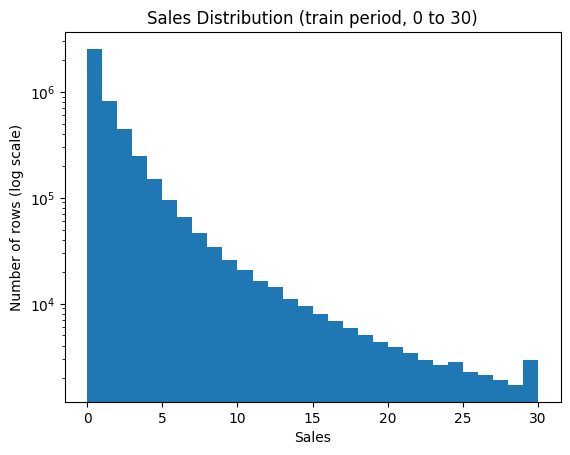

In [ ]:
# Graph : sales distribution
plt.hist(train_part["sales"], bins=range(0, 31))
plt.yscale("log")
plt.title("Sales Distribution (train period, 0 to 30)")
plt.xlabel("Sales")
plt.ylabel("Number of rows (log scale)")
plt.show()

In [ ]:
# Calculate correlation using the training data
num_cols = ["sales", "lag_7", "lag_28", "rolling_mean_7", "rolling_mean_28",
            "sell_price", "price_change", "is_weekend", "has_event", "snap", "wday", "month", "year"]

In [ ]:
corr = train_part[num_cols].corr()

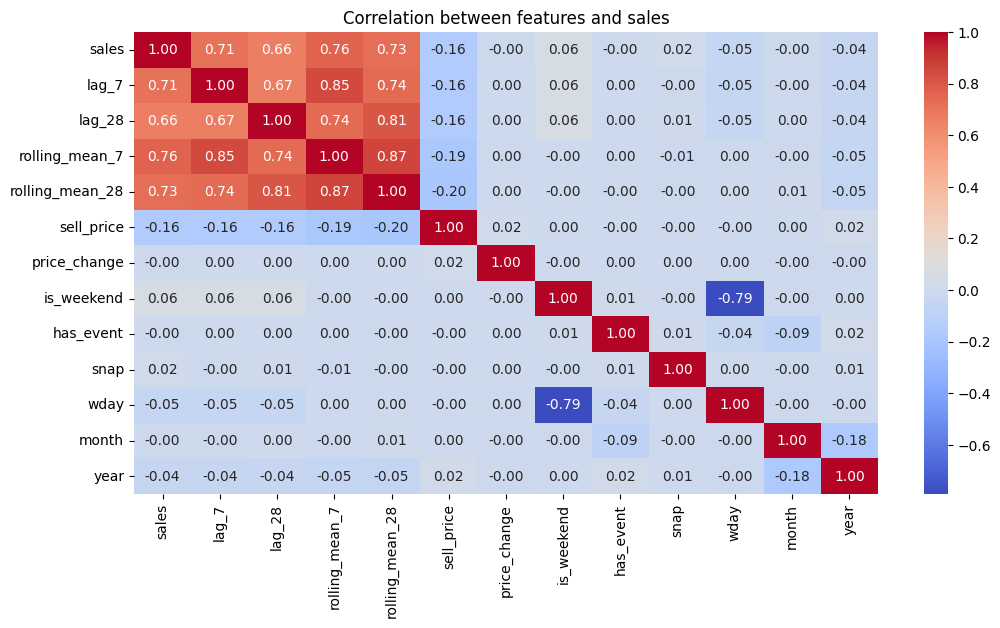

In [ ]:
plt.figure(figsize=(12, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between features and sales")
plt.show()

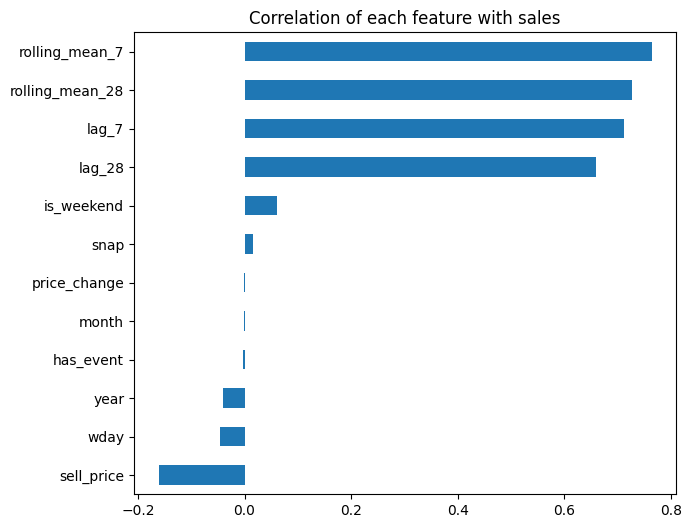

In [ ]:
# Graph : correlation of each feature with sales
corr["sales"].drop("sales").sort_values().plot(kind="barh", figsize=(7, 6))
plt.title("Correlation of each feature with sales")
plt.show()

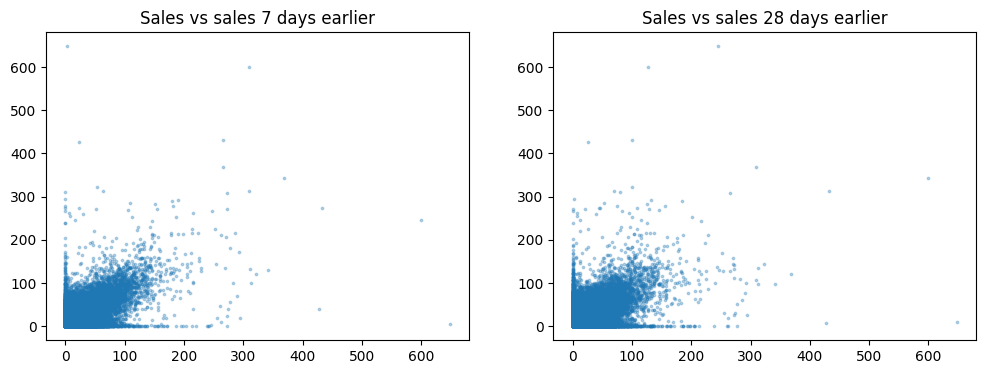

In [ ]:
# Graph : Sales vs lag_7 and lag_28

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(train_part["lag_7"], train_part["sales"], s=3, alpha=0.3)
axes[0].set_title("Sales vs sales 7 days earlier")

axes[1].scatter(train_part["lag_28"], train_part["sales"], s=3, alpha=0.3)
axes[1].set_title("Sales vs sales 28 days earlier")

plt.show()

In [ ]:
df.isna().sum()

,0
item_id,0
store_id,0
sales,0
date,0
wday,0
month,0
year,0
snap,0
sell_price,0
is_weekend,0


In [ ]:
id_cols = ["item_id", "store_id", "date", "sales"]

In [ ]:
df_7 = df[id_cols + FEATURES_7].dropna().reset_index(drop=True)
df_28 = df[id_cols + FEATURES_28].dropna().reset_index(drop=True)

In [ ]:
df_7.isna().sum().sum(), df_28.isna().sum().sum()

(np.int64(0), np.int64(0))

In [ ]:
df_7.shape, df_28.shape

((4722785, 26), (4594798, 26))

In [ ]:
OUT_PROCESSED = path + "processed/"
OUT_TESTING = path + "Testing/"

def split_and_save(data, prefix):

    # Split data into train, validation and test sets
    train = data[data["date"] < val_start]
    val = data[(data["date"] >= val_start) & (data["date"] < test_start)]
    test = data[data["date"] >= test_start]

    # Reset indexes
    train = train.reset_index(drop=True)
    val = val.reset_index(drop=True)
    test = test.reset_index(drop=True)

    # Save train and validation in processed/, and test in Testing/
    train.to_parquet(f"{OUT_PROCESSED}{prefix}_train.parquet", index=False)
    val.to_parquet(f"{OUT_PROCESSED}{prefix}_val.parquet", index=False)
    test.to_parquet(f"{OUT_TESTING}{prefix}_test.parquet", index=False)

    # Display dataset sizes
    print(prefix, "saved successfully")
    print("Train:", len(train), "| Validation:", len(val), "| Test:", len(test))

In [ ]:
split_and_save(df_7, "ca1_h7")
split_and_save(df_28, "ca1_h28")

ca1_h7 saved successfully
Train: 4552041 | Validation: 85372 | Test: 85372
ca1_h28 saved successfully
Train: 4424067 | Validation: 85359 | Test: 85372


In [ ]:
for prefix in ["ca1_h7", "ca1_h28"]:
    for split in ["train", "val", "test"]:
        folder = OUT_TESTING if split == "test" else OUT_PROCESSED
        data = pd.read_parquet(f"{folder}{prefix}_{split}.parquet")
        print(prefix, split, len(data))

print("All 6 datasets loaded successfully!")

ca1_h7 train 4552041
ca1_h7 val 85372
ca1_h7 test 85372
ca1_h28 train 4424067
ca1_h28 val 85359
ca1_h28 test 85372
All 6 datasets loaded successfully!
